In [1]:
import pandas as pd

df = pd.read_csv("supermarketsales.csv")

print("First 5 records:")
display(df.head())

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nData types:")
print(df.dtypes)

First 5 records:


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,Cost of goods sold,Gross margin percentage,Gross income,Customer stratification rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


Number of rows: 1000
Number of columns: 17

Data types:
Invoice ID                         object
Branch                             object
City                               object
Customer type                      object
Gender                             object
Product line                       object
Unit price                        float64
Quantity                            int64
Tax 5%                            float64
Total                             float64
Date                               object
Time                               object
Payment                            object
Cost of goods sold                float64
Gross margin percentage           float64
Gross income                      float64
Customer stratification rating    float64
dtype: object


Missing values are checked across all columns to identify incomplete records and determine whether missingness could affect the analysis.

In [2]:
missing = df.isnull().sum()

print("Missing values by column:")
print(missing)
print("\nTotal missing values:", missing.sum())
print("Rows with missing values:", df.isnull().any(axis=1).sum())

Missing values by column:
Invoice ID                        0
Branch                            0
City                              0
Customer type                     0
Gender                            0
Product line                      0
Unit price                        0
Quantity                          0
Tax 5%                            0
Total                             0
Date                              0
Time                              0
Payment                           0
Cost of goods sold                0
Gross margin percentage           0
Gross income                      0
Customer stratification rating    0
dtype: int64

Total missing values: 0
Rows with missing values: 0


Duplicate records are checked using both complete rows and Invoice ID, which serves as the transaction identifier.

In [3]:
print("Full-row duplicates:", df.duplicated().sum())

print("Duplicate Invoice IDs:",
      df["Invoice ID"].duplicated().sum())

print("Unique Invoice IDs:",
      df["Invoice ID"].nunique())

Full-row duplicates: 0
Duplicate Invoice IDs: 0
Unique Invoice IDs: 1000


The data types are examined to identify columns stored in unsuitable formats, particularly Date and Time.

In [4]:
print(df[["Date", "Time"]].dtypes)

dates = pd.to_datetime(
    df["Date"], format="%m/%d/%Y", errors="coerce"
)

times = pd.to_datetime(
    df["Time"], format="%H:%M", errors="coerce"
)

print("\nInvalid dates:", dates.isna().sum())
print("Invalid times:", times.isna().sum())

Date    object
Time    object
dtype: object

Invalid dates: 0
Invalid times: 0


Categorical columns are examined for spelling differences, inconsistent capitalization, extra whitespace, and overlapping location labels.

In [5]:
cat_cols = [
    "Branch", "City", "Customer type",
    "Gender", "Product line", "Payment"
]

for col in cat_cols:
    print(f"\n{col}:")
    print(sorted(df[col].unique()))

    normalized = df[col].str.strip().str.lower()

    print("Original unique:", df[col].nunique())
    print("Normalized unique:", normalized.nunique())
    print("Whitespace issues:",
          (df[col] != df[col].str.strip()).sum())

print("\nBranch-City relationship:")
display(pd.crosstab(df["Branch"], df["City"]))


Branch:
['A', 'B', 'C']
Original unique: 3
Normalized unique: 3
Whitespace issues: 0

City:
['Mandalay', 'Naypyitaw', 'Yangon']
Original unique: 3
Normalized unique: 3
Whitespace issues: 0

Customer type:
['Member', 'Normal']
Original unique: 2
Normalized unique: 2
Whitespace issues: 0

Gender:
['Female', 'Male']
Original unique: 2
Normalized unique: 2
Whitespace issues: 0

Product line:
['Electronic accessories', 'Fashion accessories', 'Food and beverages', 'Health and beauty', 'Home and lifestyle', 'Sports and travel']
Original unique: 6
Normalized unique: 6
Whitespace issues: 0

Payment:
['Cash', 'Credit card', 'Ewallet']
Original unique: 3
Normalized unique: 3
Whitespace issues: 0

Branch-City relationship:


City,Mandalay,Naypyitaw,Yangon
Branch,,,
A,0,0,340
B,332,0,0
C,0,328,0


Numerical values are checked for invalid ranges and mathematical inconsistencies. Customer ratings, quantities, prices, and financial relationships are examined.

In [6]:
import numpy as np

print("Invalid ratings:",
      (~df["Customer stratification rating"].between(0, 10)).sum())

print("Invalid quantities:", (df["Quantity"] <= 0).sum())
print("Invalid unit prices:", (df["Unit price"] <= 0).sum())

print("\nRating range:",
      df["Customer stratification rating"].min(),
      "to",
      df["Customer stratification rating"].max())

checks = {
    "Cost = Price × Quantity":
        np.isclose(
            df["Cost of goods sold"],
            df["Unit price"] * df["Quantity"]
        ),

    "Tax = 5% of Cost":
        np.isclose(
            df["Tax 5%"],
            df["Cost of goods sold"] * 0.05
        ),

    "Total = Cost + Tax":
        np.isclose(
            df["Total"],
            df["Cost of goods sold"] + df["Tax 5%"]
        ),

    "Gross income = Tax":
        np.isclose(
            df["Gross income"],
            df["Tax 5%"]
        )
}

for name, result in checks.items():
    print(name, ":", result.sum(), "/ 1000")

Invalid ratings: 0
Invalid quantities: 0
Invalid unit prices: 0

Rating range: 4.0 to 10.0
Cost = Price × Quantity : 1000 / 1000
Tax = 5% of Cost : 1000 / 1000
Total = Cost + Tax : 1000 / 1000
Gross income = Tax : 1000 / 1000


Outliers are identified using the Interquartile Range (IQR) method. Values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR are flagged as potential outliers.

In [7]:
numeric_cols = df.select_dtypes(include="number").columns

outlier_results = []

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_results.append([col, count])

outlier_table = pd.DataFrame(
    outlier_results,
    columns=["Column", "Outlier Count"]
)

display(outlier_table)

,Column,Outlier Count
0,Unit price,0
1,Quantity,0
2,Tax 5%,9
3,Total,9
4,Cost of goods sold,9
5,Gross margin percentage,0
6,Gross income,9
7,Customer stratification rating,0


No missing values or duplicates were found, so no records were removed. The original 1,000 transactions were preserved for further analysis.

Date and Time were originally stored as text. These columns are converted to appropriate temporal formats to support chronological and time-based analysis.

In [9]:
df_clean = df.copy()

df_clean["Date"] = pd.to_datetime(
    df_clean["Date"], format="%m/%d/%Y"
)

df_clean["Time"] = pd.to_datetime(
    df_clean["Time"], format="%H:%M"
).dt.time

print(df_clean[["Date", "Time"]].head())
print("\nDate type:", df_clean["Date"].dtype)
print("Time sample type:", type(df_clean["Time"].iloc[0]))

        Date      Time
0 2019-01-05  13:08:00
1 2019-03-08  10:29:00
2 2019-03-03  13:23:00
3 2019-01-27  20:33:00
4 2019-02-08  10:37:00

Date type: datetime64[ns]
Time sample type: <class 'datetime.time'>


Three derived variables—Hour, Weekday, and Month—are created to analyze hourly sales activity, differences between weekdays, and monthly sales patterns.

In [10]:
df_clean["Hour"] = df_clean["Time"].apply(lambda t: t.hour)

df_clean["Weekday"] = df_clean["Date"].dt.day_name()

df_clean["Month"] = df_clean["Date"].dt.month

display(df_clean[
    ["Date", "Time", "Hour", "Weekday", "Month"]
].head())

,Date,Time,Hour,Weekday,Month
0,2019-01-05,13:08:00,13,Saturday,1
1,2019-03-08,10:29:00,10,Friday,3
2,2019-03-03,13:23:00,13,Sunday,3
3,2019-01-27,20:33:00,20,Sunday,1
4,2019-02-08,10:37:00,10,Friday,2


The nine high-value transactions were retained because their financial calculations are consistent and there is no evidence that they are erroneous. Redundant financial columns and overlapping Branch–City information were also preserved in the cleaned dataset for transparency, but should be considered during feature selection.

In [11]:
filename = "23L_0646_A2_supermarket_cleaned.csv"

df_clean.to_csv(filename, index=False, date_format="%Y-%m-%d")

saved_df = pd.read_csv(filename)

print("Saved dataset shape:", saved_df.shape)
print("Missing values:", saved_df.isna().sum().sum())
print("Duplicate Invoice IDs:",
      saved_df["Invoice ID"].duplicated().sum())
print("Derived columns:",
      ["Hour", "Weekday", "Month"])

Saved dataset shape: (1000, 20)
Missing values: 0
Duplicate Invoice IDs: 0
Derived columns: ['Hour', 'Weekday', 'Month']


Numerical variables (Unit price, Quantity, Total, and Customer stratification rating) are examined using descriptive statistics, histograms, and boxplots. Histograms show the distribution and skewness, while boxplots help identify potential outliers. Mean, median, standard deviation, and skewness are calculated to support the visual observations.

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = [
    "Unit price",
    "Quantity",
    "Total",
    "Customer stratification rating"
]

stats = df_clean[numeric_cols].agg(
    ["mean", "median", "std", "min", "max", "skew"]
).T.round(2)

display(stats)

,mean,median,std,min,max,skew
Unit price,55.67,55.23,26.49,10.08,99.96,0.01
Quantity,5.51,5.00,2.92,1.00,10.00,0.01
Total,322.97,253.85,245.89,10.68,1042.65,0.89
Customer stratification rating,6.97,7.00,1.72,4.00,10.00,0.01


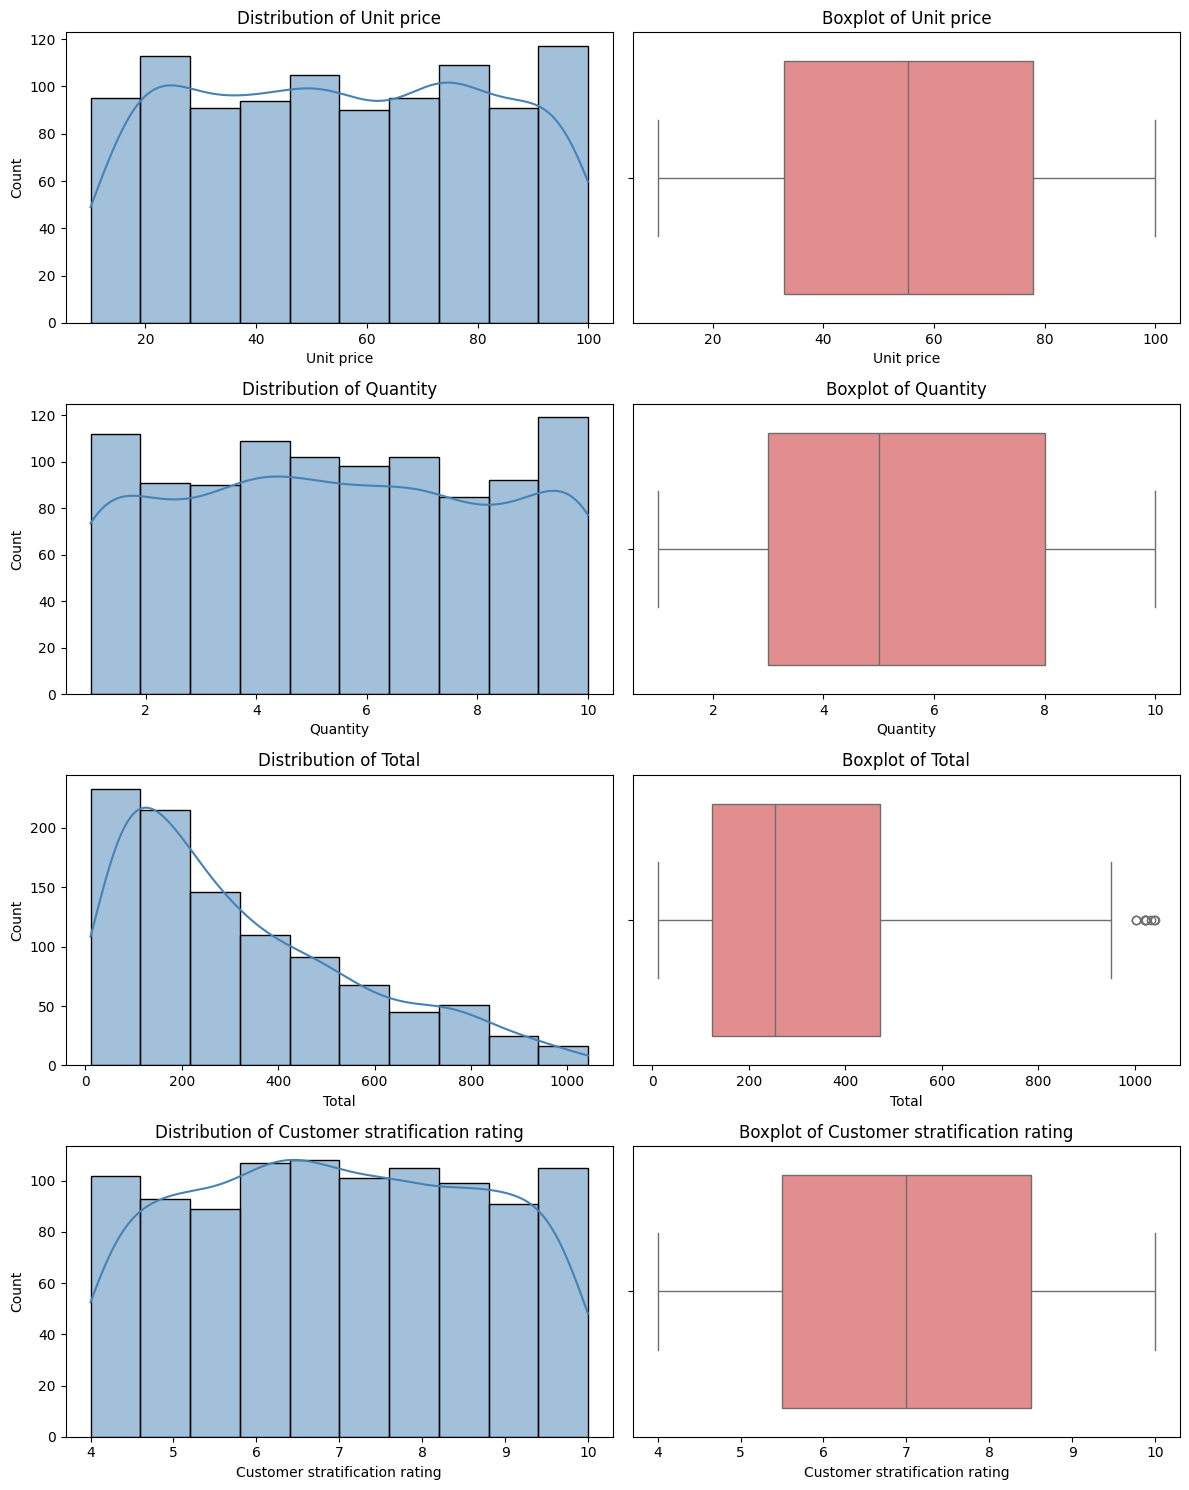

In [13]:
fig, axes = plt.subplots(4, 2, figsize=(12, 15))

for i, col in enumerate(numeric_cols):

    sns.histplot(
        df_clean[col],
        bins=10,
        kde=True,
        ax=axes[i, 0],
        color="steelblue"
    )
    axes[i, 0].set_title(f"Distribution of {col}")

    sns.boxplot(
        x=df_clean[col],
        ax=axes[i, 1],
        color="lightcoral"
    )
    axes[i, 1].set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

Categorical variables (Branch, Product line, Customer type, and Payment) are analyzed using frequency counts and bar charts. Bar charts are appropriate because they allow direct comparison of category frequencies, while percentages show the relative proportion of transactions.

In [14]:
categorical_cols = [
    "Branch",
    "Product line",
    "Customer type",
    "Payment"
]

for col in categorical_cols:
    print(f"\n{col}")

    freq = df_clean[col].value_counts()

    summary = pd.DataFrame({
        "Count": freq,
        "Percentage (%)": (freq / len(df_clean) * 100).round(2)
    })

    display(summary)


Branch


,Count,Percentage (%)
Branch,,
A,340,34.0
B,332,33.2
C,328,32.8



Product line


,Count,Percentage (%)
Product line,,
Fashion accessories,178,17.8
Food and beverages,174,17.4
Electronic accessories,170,17.0
Sports and travel,166,16.6
Home and lifestyle,160,16.0
Health and beauty,152,15.2



Customer type


,Count,Percentage (%)
Customer type,,
Member,501,50.1
Normal,499,49.9



Payment


,Count,Percentage (%)
Payment,,
Ewallet,345,34.5
Cash,344,34.4
Credit card,311,31.1


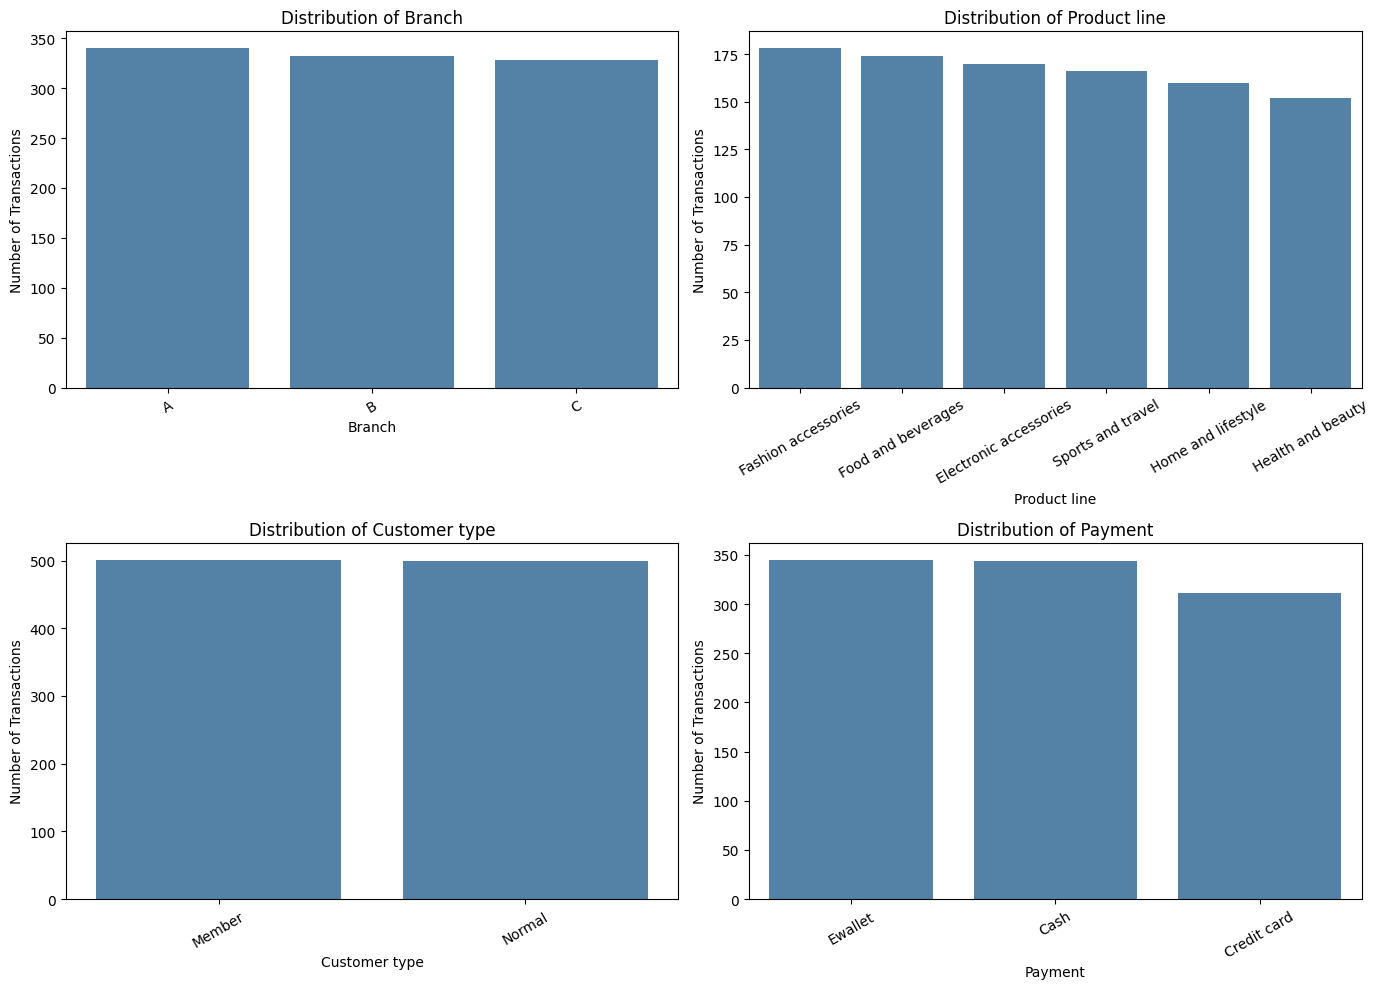

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.flatten(), categorical_cols):

    order = df_clean[col].value_counts().index

    sns.countplot(
        data=df_clean,
        x=col,
        order=order,
        ax=ax,
        color="steelblue"
    )

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of Transactions")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

The relationship between Quantity and Total is examined using a scatterplot and Pearson correlation. A scatterplot shows how transaction values change with purchase quantity, while correlation measures the strength and direction of their linear relationship.

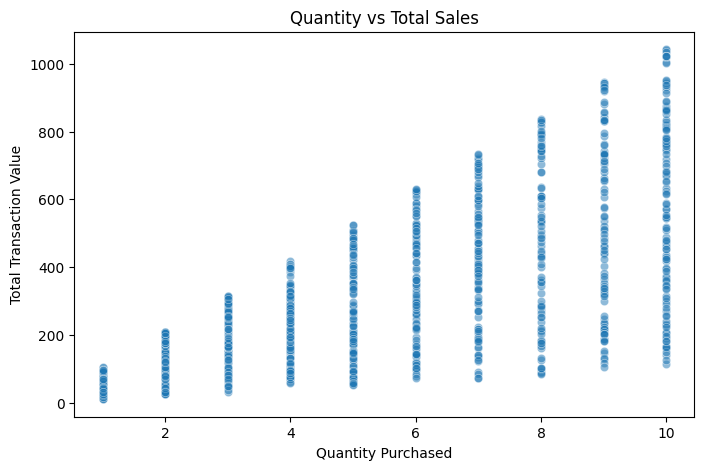

Pearson correlation: 0.706


In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="Quantity",
    y="Total",
    alpha=0.5
)

plt.title("Quantity vs Total Sales")
plt.xlabel("Quantity Purchased")
plt.ylabel("Total Transaction Value")
plt.show()

corr = df_clean["Quantity"].corr(df_clean["Total"])
print("Pearson correlation:", round(corr, 3))

Total transaction values are compared across product lines using boxplots and group statistics. Boxplots are appropriate because they show differences in medians, variability, and potential outliers between categories.

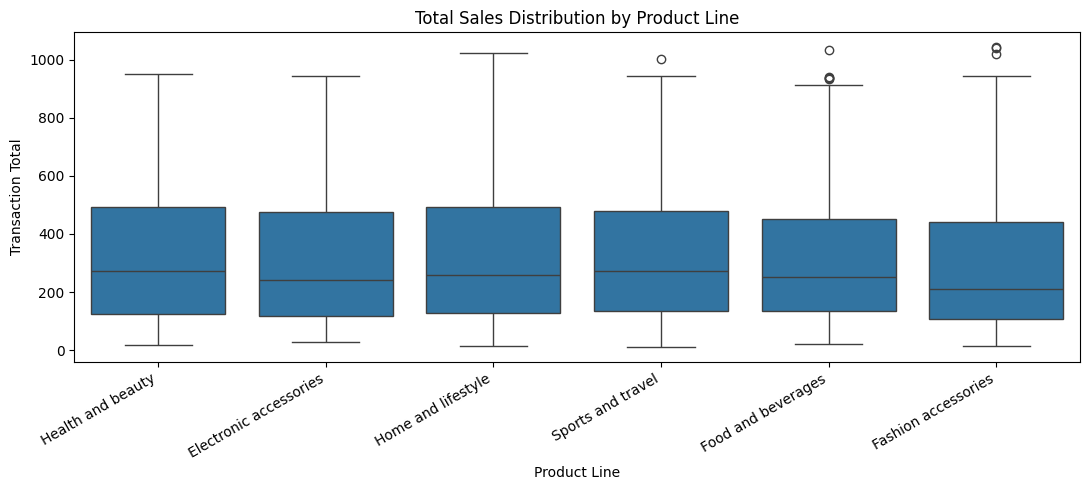

,count,mean,median,sum
Product line,,,,
Electronic accessories,170,319.63,241.22,54337.53
Fashion accessories,178,305.09,211.65,54305.90
Food and beverages,174,322.67,252.49,56144.84
Health and beauty,152,323.64,272.31,49193.74
Home and lifestyle,160,336.64,258.19,53861.91
Sports and travel,166,332.07,270.93,55122.83


In [17]:
plt.figure(figsize=(11, 5))

sns.boxplot(
    data=df_clean,
    x="Product line",
    y="Total"
)

plt.xticks(rotation=30, ha="right")
plt.title("Total Sales Distribution by Product Line")
plt.xlabel("Product Line")
plt.ylabel("Transaction Total")
plt.tight_layout()
plt.show()

product_stats = df_clean.groupby("Product line")["Total"].agg(
    ["count", "mean", "median", "sum"]
).round(2)

display(product_stats)

Sales performance is compared across supermarket branches using average transaction values and total revenue. A bar chart is used to compare the average transaction value across branches.

,count,mean,sum
Branch,,,
A,340,312.35,106200.37
B,332,319.87,106197.67
C,328,337.10,110568.71


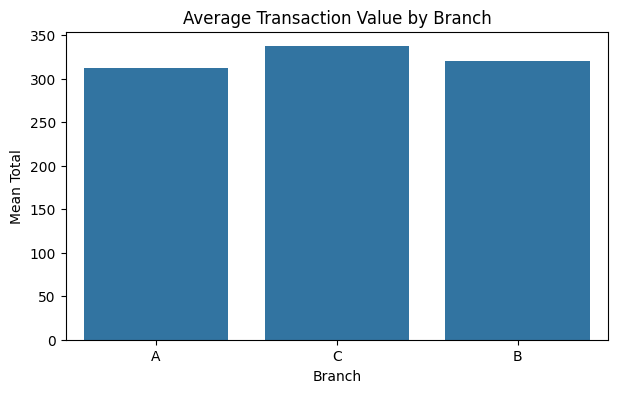

In [18]:
branch_stats = df_clean.groupby("Branch")["Total"].agg(
    ["count", "mean", "sum"]
).round(2)

display(branch_stats)

plt.figure(figsize=(7, 4))

sns.barplot(
    data=df_clean,
    x="Branch",
    y="Total",
    estimator="mean",
    errorbar=None
)

plt.title("Average Transaction Value by Branch")
plt.xlabel("Branch")
plt.ylabel("Mean Total")
plt.show()

The relationship between Branch and Payment method is examined using a contingency table and a 100% stacked bar chart. Percentages are used to compare payment preferences fairly across branches with slightly different transaction counts.

Payment,Cash,Credit card,Ewallet
Branch,,,
A,110,104,126
B,110,109,113
C,124,98,106


Payment,Cash,Credit card,Ewallet
Branch,,,
A,32.4,30.6,37.1
B,33.1,32.8,34.0
C,37.8,29.9,32.3


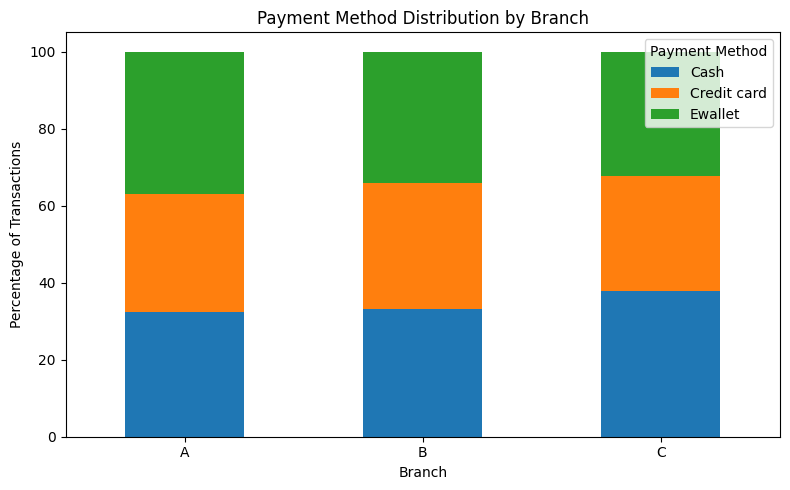

In [19]:
payment_counts = pd.crosstab(
    df_clean["Branch"],
    df_clean["Payment"]
)

payment_percent = pd.crosstab(
    df_clean["Branch"],
    df_clean["Payment"],
    normalize="index"
) * 100

display(payment_counts)
display(payment_percent.round(1))

payment_percent.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Payment Method Distribution by Branch")
plt.xlabel("Branch")
plt.ylabel("Percentage of Transactions")
plt.legend(title="Payment Method")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

This analysis compares average transaction values between Member and Normal customers across different branches. A grouped bar chart is used to determine whether customer-type spending differences remain consistent across locations.

count    mean
Branch Customer type               
A      Member           167  321.18
       Normal           173  303.83
B      Member           165  325.48
       Normal           167  314.33
C      Member           169  336.58
       Normal           159  337.66

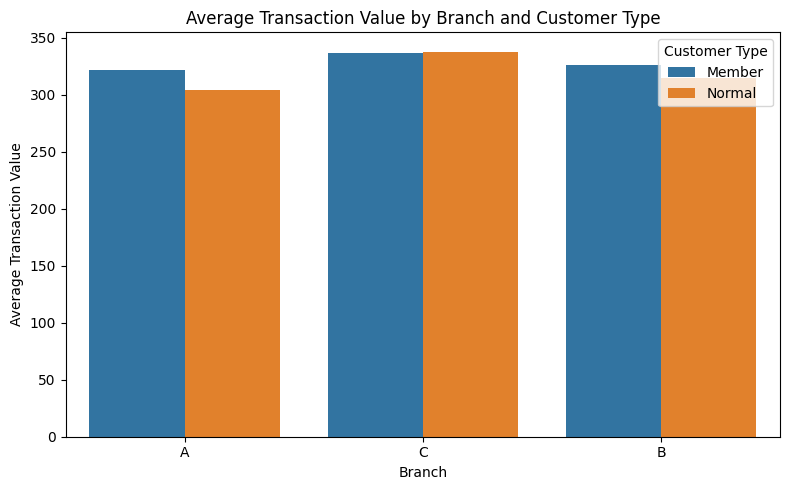

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

summary1 = df_clean.groupby( ["Branch", "Customer type"])["Total"].agg(["count", "mean"]).round(2)

display(summary1)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_clean,
    x="Branch",
    y="Total",
    hue="Customer type",
    estimator="mean",
    errorbar=None
)

plt.title("Average Transaction Value by Branch and Customer Type")
plt.xlabel("Branch")
plt.ylabel("Average Transaction Value")
plt.legend(title="Customer Type")
plt.tight_layout()
plt.show()

This analysis examines how average transaction values differ across product lines and branches. A heatmap is used because it allows easy comparison of two categorical variables using average sales as the numerical measure.

Branch,A,B,C
Product line,,,
Electronic accessories,305.29,310.03,344.89
Fashion accessories,320.25,264.73,331.69
Food and beverages,295.92,304.30,360.10
Health and beauty,268.04,376.99,319.53
Home and lifestyle,344.88,350.98,308.79
Sports and travel,328.35,322.39,350.27


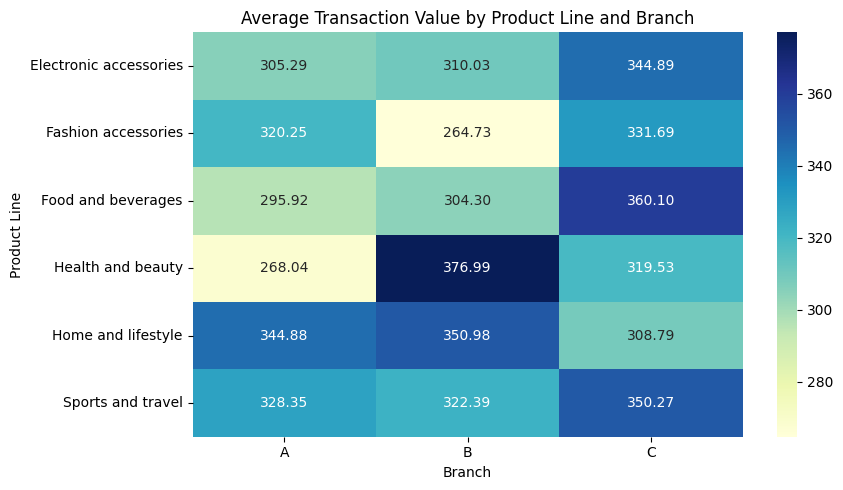

In [21]:
summary2 = df_clean.pivot_table(
    index="Product line",
    columns="Branch",
    values="Total",
    aggfunc="mean"
).round(2)

display(summary2)

plt.figure(figsize=(9, 5))

sns.heatmap(
    summary2,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu"
)

plt.title("Average Transaction Value by Product Line and Branch")
plt.xlabel("Branch")
plt.ylabel("Product Line")
plt.tight_layout()
plt.show()

Product lines are compared using total revenue and average transaction value. Two bar charts are used to show whether categories generating the most revenue also have the highest average purchase value. Total revenue reflects overall contribution, while average transaction value accounts for differences in transaction frequency.

,Total_Revenue,Average_Transaction,Transactions
Product line,,,
Food and beverages,56144.84,322.67,174
Sports and travel,55122.83,332.07,166
Electronic accessories,54337.53,319.63,170
Fashion accessories,54305.90,305.09,178
Home and lifestyle,53861.91,336.64,160
Health and beauty,49193.74,323.64,152


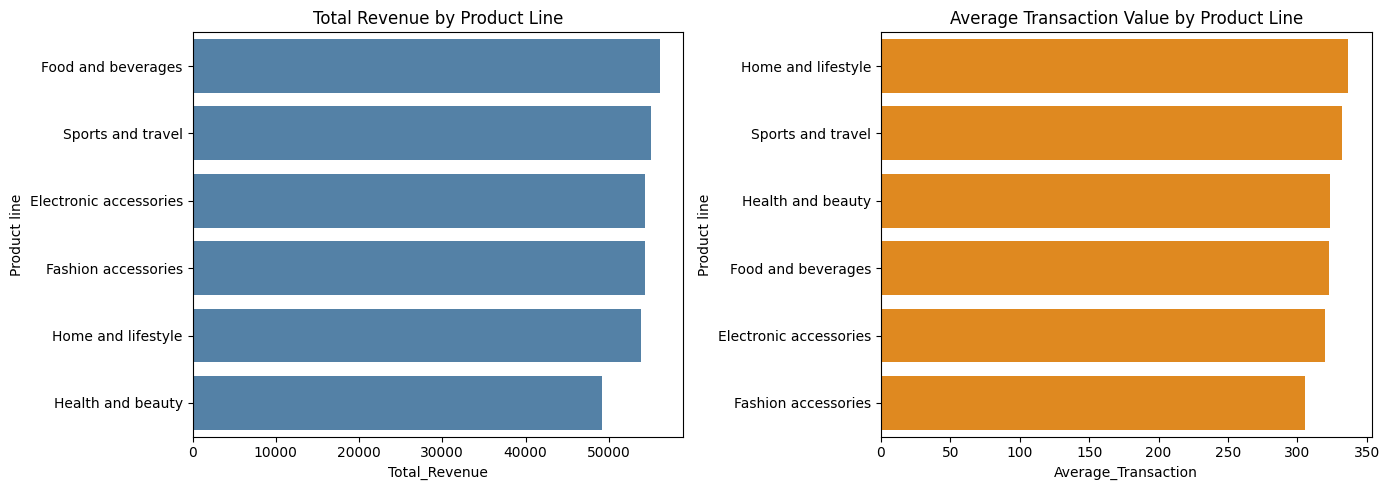

In [22]:
product_sales = df_clean.groupby("Product line")["Total"].agg(
    Total_Revenue="sum",
    Average_Transaction="mean",
    Transactions="count"
).round(2)

display(product_sales.sort_values("Total_Revenue", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=product_sales.reset_index(),
    x="Total_Revenue",
    y="Product line",
    order=product_sales.sort_values(
        "Total_Revenue", ascending=False
    ).index,
    ax=axes[0],
    color="steelblue"
)
axes[0].set_title("Total Revenue by Product Line")

sns.barplot(
    data=product_sales.reset_index(),
    x="Average_Transaction",
    y="Product line",
    order=product_sales.sort_values(
        "Average_Transaction", ascending=False
    ).index,
    ax=axes[1],
    color="darkorange"
)
axes[1].set_title("Average Transaction Value by Product Line")

plt.tight_layout()
plt.show()

Branches are compared using average transaction value, quantity, and customer ratings. Grouped statistics and boxplots are used to determine whether differences between branches are substantial compared with the variation within each branch.

,Transactions,Total_Sales,Mean_Sales,Sales_SD,Mean_Quantity,Mean_Rating
Branch,,,,,,
A,340,106200.37,312.35,231.64,5.47,7.03
B,332,106197.67,319.87,242.45,5.48,6.82
C,328,110568.71,337.10,263.16,5.58,7.07


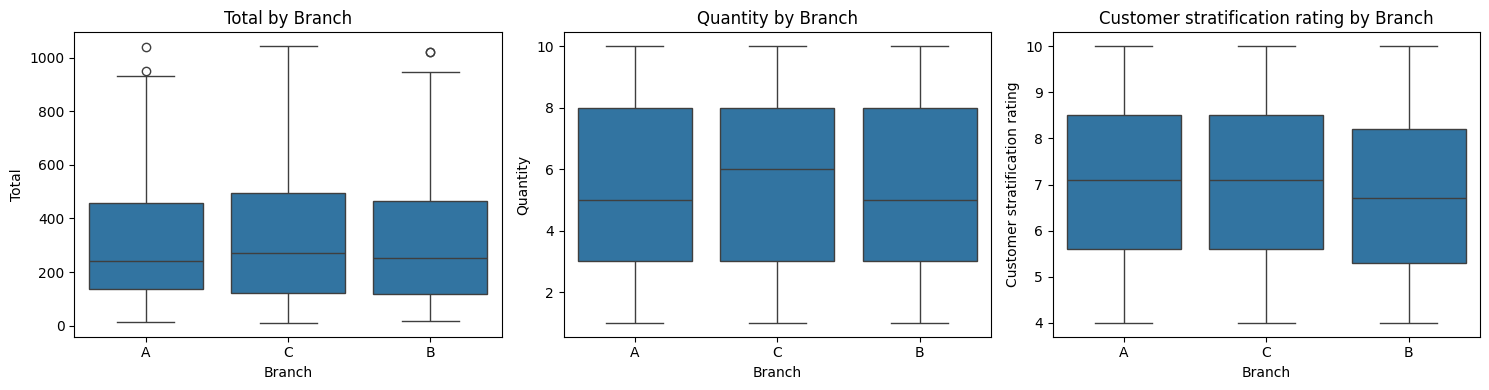

In [23]:
branch_summary = df_clean.groupby("Branch").agg(
    Transactions=("Total", "count"),
    Total_Sales=("Total", "sum"),
    Mean_Sales=("Total", "mean"),
    Sales_SD=("Total", "std"),
    Mean_Quantity=("Quantity", "mean"),
    Mean_Rating=("Customer stratification rating", "mean")
).round(2)

display(branch_summary)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

variables = [
    "Total",
    "Quantity",
    "Customer stratification rating"
]

for ax, col in zip(axes, variables):
    sns.boxplot(
        data=df_clean,
        x="Branch",
        y=col,
        ax=ax
    )
    ax.set_title(f"{col} by Branch")

plt.tight_layout()
plt.show()

Average transaction values are compared across customer types and payment methods using summary statistics and boxplots. Boxplots help determine whether differences in average spending are meaningful relative to the variation within each group.

,count,mean,median,std
Customer type,,,,
Member,501,327.79,266.03,247.99
Normal,499,318.12,237.43,243.90


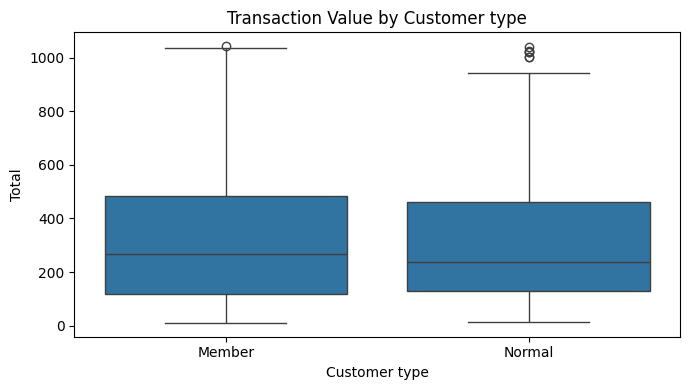

,count,mean,median,std
Payment,,,,
Cash,344,326.18,262.96,242.66
Credit card,311,324.01,239.59,257.11
Ewallet,345,318.82,253.68,239.31


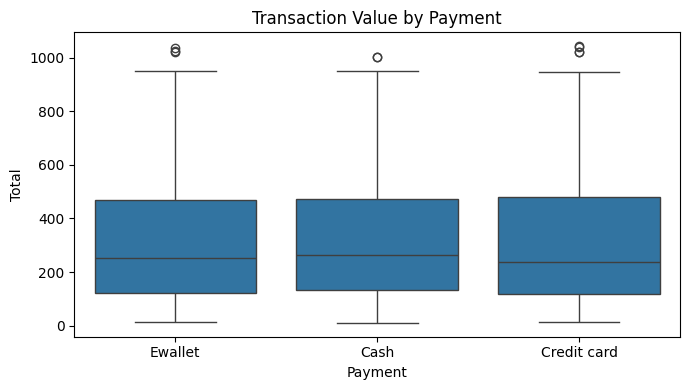

In [24]:
for col in ["Customer type", "Payment"]:
    summary = df_clean.groupby(col)["Total"].agg(
        ["count", "mean", "median", "std"]
    ).round(2)

    display(summary)

    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df_clean, x=col, y="Total")
    plt.title(f"Transaction Value by {col}")
    plt.tight_layout()
    plt.show()

Sales are analyzed by transaction hour and weekday using total revenue and transaction counts. Line and bar charts are appropriate for identifying temporal patterns and comparing sales activity across different time periods.

,Revenue,Transactions,Average
Hour,,,
10,31421.48,101,311.10
11,30377.33,90,337.53
12,26065.88,89,292.88
13,34723.23,103,337.12
14,30828.40,83,371.43
15,31179.51,102,305.68
16,25226.32,77,327.61
17,24445.22,74,330.34
18,26030.34,93,279.90


,Revenue,Transactions,Average
Weekday,,,
Monday,37899.08,125,303.19
Tuesday,51482.25,158,325.84
Wednesday,43731.14,143,305.81
Thursday,45349.25,138,328.62
Friday,43926.34,139,316.02
Saturday,56120.81,164,342.20
Sunday,44457.89,133,334.27


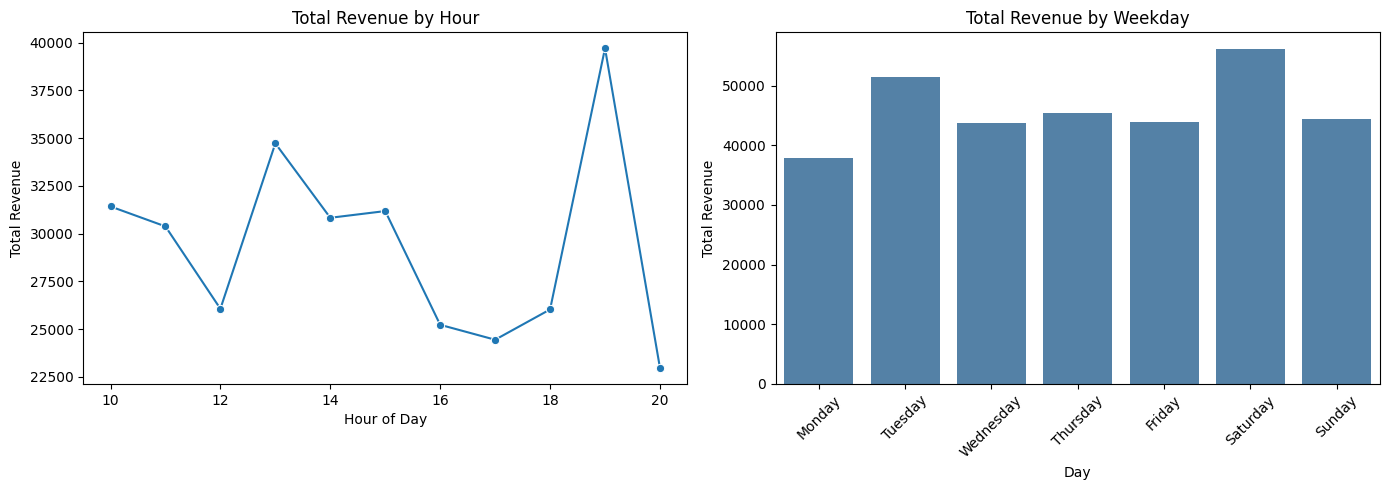

In [25]:
hourly = df_clean.groupby("Hour")["Total"].agg(
    Revenue="sum",
    Transactions="count",
    Average="mean"
)

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

daily = df_clean.groupby("Weekday")["Total"].agg(
    Revenue="sum",
    Transactions="count",
    Average="mean"
).reindex(weekday_order)

display(hourly.round(2))
display(daily.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.lineplot(
    x=hourly.index,
    y=hourly["Revenue"],
    marker="o",
    ax=axes[0]
)
axes[0].set_title("Total Revenue by Hour")
axes[0].set_xlabel("Hour of Day")
axes[0].set_ylabel("Total Revenue")

sns.barplot(
    x=daily.index,
    y=daily["Revenue"],
    ax=axes[1],
    color="steelblue"
)
axes[1].set_title("Total Revenue by Weekday")
axes[1].set_xlabel("Day")
axes[1].set_ylabel("Total Revenue")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

Customer ratings are examined against Unit price, Quantity, Product line, and Branch. Pearson correlation measures numerical relationships, while boxplots compare rating distributions across categorical groups. These methods help determine whether customer satisfaction is associated with transaction characteristics.

,Customer stratification rating
Customer stratification rating,1.000
Unit price,-0.009
Quantity,-0.016
Total,-0.036


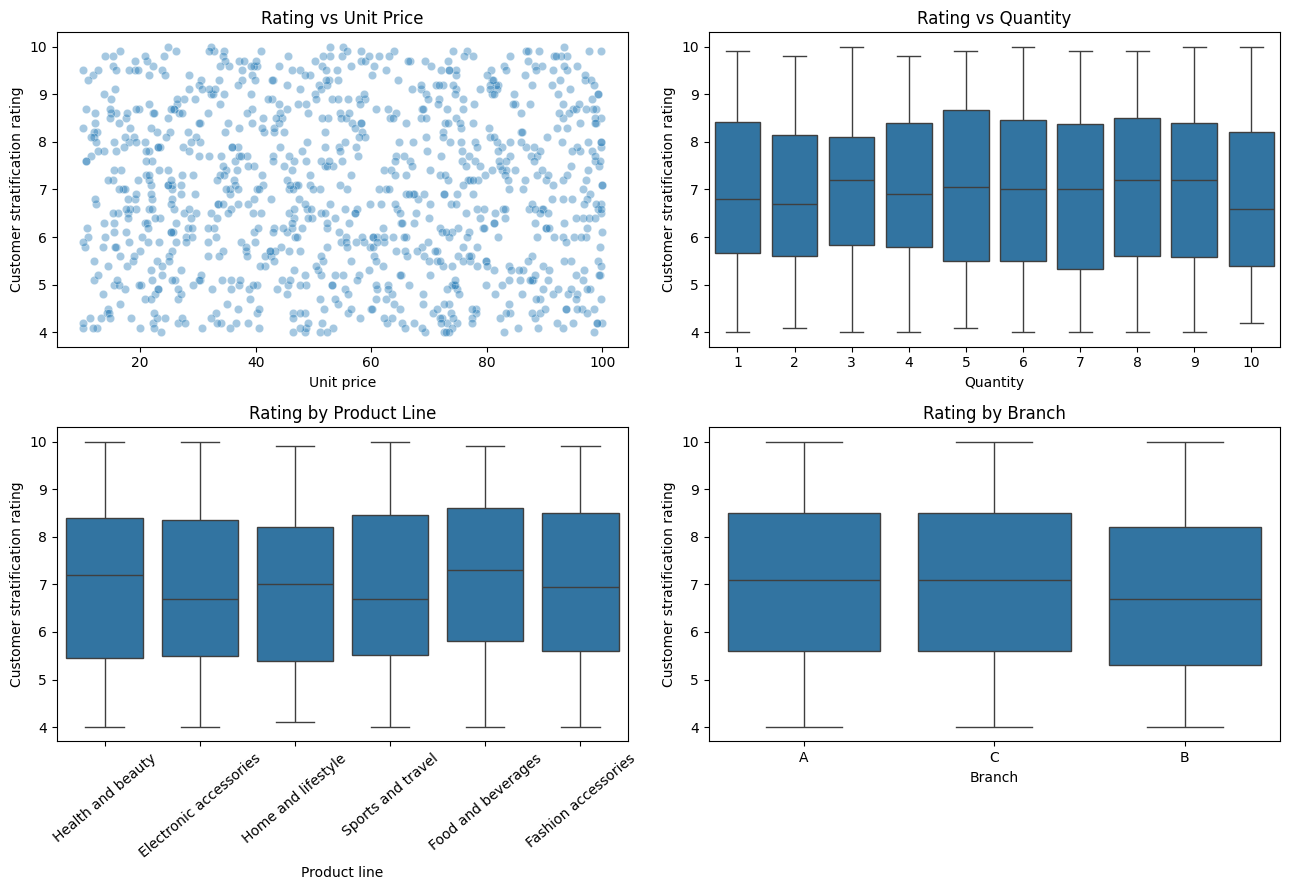


Average rating by product line:


,Customer stratification rating
Product line,
Electronic accessories,6.92
Fashion accessories,7.03
Food and beverages,7.11
Health and beauty,7.00
Home and lifestyle,6.84
Sports and travel,6.92



Average rating by branch:


,Customer stratification rating
Branch,
A,7.03
B,6.82
C,7.07


In [26]:
rating = "Customer stratification rating"

# Numerical relationships
corr = df_clean[
    [rating, "Unit price", "Quantity", "Total"]
].corr()[rating].round(3)

display(corr)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.scatterplot(
    data=df_clean, x="Unit price", y=rating,
    alpha=0.4, ax=axes[0, 0]
)
axes[0, 0].set_title("Rating vs Unit Price")

sns.boxplot(
    data=df_clean, x="Quantity", y=rating,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Rating vs Quantity")

sns.boxplot(
    data=df_clean, x="Product line", y=rating,
    ax=axes[1, 0]
)
axes[1, 0].tick_params(axis="x", rotation=40)
axes[1, 0].set_title("Rating by Product Line")

sns.boxplot(
    data=df_clean, x="Branch", y=rating,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Rating by Branch")

plt.tight_layout()
plt.show()

print("\nAverage rating by product line:")
display(df_clean.groupby("Product line")[rating].mean().round(2))

print("\nAverage rating by branch:")
display(df_clean.groupby("Branch")[rating].mean().round(2))